| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../20_INVESTIGACION/20_1_papers.ipynb) | [⏩](../20_INVESTIGACION/20_3_Diseño_experimental.ipynb) |

# 20.2 REPRODUCIR PAPERS: UN EXPERIMENTO SINDy REDUCIDO

Reproducir investigación exige definir qué resultado se intenta reconstruir y qué decisiones se conservan. Usaremos como referencia [Brunton, Proctor y Kutz: identificación dispersa de sistemas dinámicos](https://arxiv.org/abs/1509.03580). Implementaremos el mecanismo de biblioteca de funciones y mínimos cuadrados con umbral en un oscilador lineal amortiguado.

**Alcance explícito.** Este es un experimento reducido y original que verifica una idea del método SINDy. No reproduce una figura publicada, el caso de fluidos ni todas las configuraciones del artículo. Trabajaremos con datos generados en el cuaderno, derivadas conocidas en un control ideal y derivadas estimadas en casos ruidosos.

**Objetivos.** Formular un protocolo de reproducción, implementar una referencia transparente, validar trayectorias nuevas y medir sensibilidad al ruido. Bibliotecas: NumPy, SciPy y Matplotlib. Requisitos: ODE y regresión lineal.

## 1. Definir una afirmación verificable

Nuestra afirmación operativa será: «con estados bien muestreados, una biblioteca que contiene los términos correctos y derivadas suficientemente precisas, la regresión con umbral recupera la estructura lineal de un oscilador amortiguado».

Esta frase explicita tres condiciones. Si la biblioteca omite un término, el método no puede descubrirlo. Si las trayectorias apenas exploran el estado, varios términos pueden confundirse. Si el ruido domina derivadas, seleccionar términos se vuelve inestable. La reproducción debe investigar esas condiciones, no solo mostrar un caso favorable.

## 2. Modelo y solución de referencia

El estado $z=(x,y)^T$ satisface
$$x'=-\delta x+\omega y,\qquad y'=-\omega x-\delta y,$$
con $\delta=0.1$, $\omega=2$. Para $z(0)=(x_0,y_0)$,
$$x=e^{-\delta t}(x_0\cos\omega t+y_0\sin\omega t),$$
$$y=e^{-\delta t}(-x_0\sin\omega t+y_0\cos\omega t).$$
La energía $x^2+y^2$ decrece como $e^{-2\delta t}$. Conocemos ecuación y solución porque el caso es sintético. La verdad no se usará como una entrada oculta en el experimento ruidoso; servirá para evaluación y para un control positivo de la implementación.

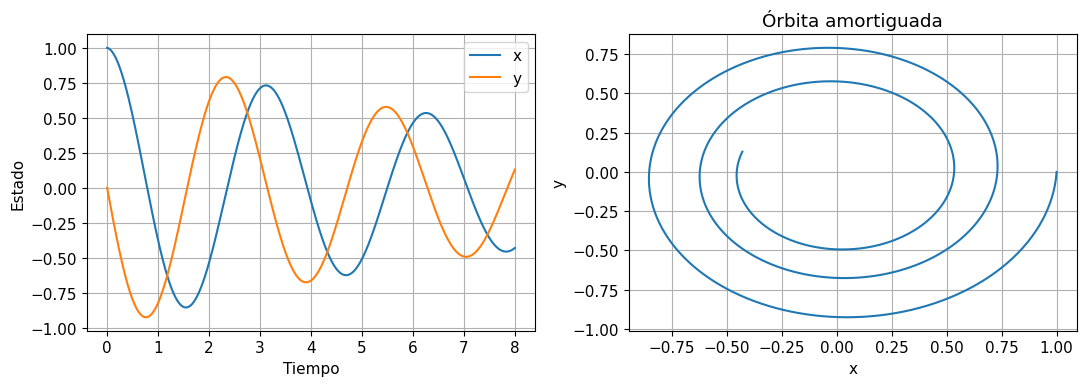

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.integrate import solve_ivp
rng = np.random.default_rng(202)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 11})
delta, omega = 0.1, 2.0

def trayectoria(t, inicial):
    t = np.asarray(t)
    c, s, dec = np.cos(omega*t), np.sin(omega*t), np.exp(-delta*t)
    x0, y0 = inicial
    return dec[:, None]*np.column_stack([x0*c+y0*s, -x0*s+y0*c])

def derivada_exacta(Z):
    return np.column_stack([-delta*Z[:, 0]+omega*Z[:, 1], -omega*Z[:, 0]-delta*Z[:, 1]])

t = np.linspace(0, 8, 801); dt = t[1]-t[0]
Z = trayectoria(t, [1.0, 0.0])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t, Z[:, 0], label="x"); axes[0].plot(t, Z[:, 1], label="y")
axes[0].set(xlabel="Tiempo", ylabel="Estado"); axes[0].legend()
axes[1].plot(Z[:, 0], Z[:, 1]); axes[1].set(xlabel="x", ylabel="y", title="Órbita amortiguada")
plt.tight_layout(); plt.show()

## 3. Biblioteca de funciones candidatas

Construimos $\Theta(Z)=[1,x,y,x^2,xy,y^2]$. Las derivadas se aproximan como $\dot Z\approx\Theta\Xi$. Cada columna de $\Xi$ corresponde a una ecuación y cada fila a una función candidata. La estructura correcta tiene solo dos términos por ecuación.

Una biblioteca excesivamente grande puede estar mal condicionada y ajustar ruido. Sus columnas tienen unidades distintas: un umbral sobre coeficientes debe considerar escalas. Aquí los estados son adimensionales y de orden uno; aplicaremos umbral en coeficientes físicos sin normalización adicional y lo documentaremos. Para unidades o escalas diferentes, sería necesaria una estrategia coherente de escalamiento.

In [2]:
nombres = ["1", "x", "y", "x²", "xy", "y²"]
def biblioteca(Z):
    x, y = Z[:, 0], Z[:, 1]
    return np.column_stack([np.ones(len(Z)), x, y, x*x, x*y, y*y])

Xi_real = np.zeros((6, 2))
Xi_real[1] = [-delta, -omega]
Xi_real[2] = [omega, -delta]

def stlsq(Theta, dZ, umbral=0.05, iteraciones=12):
    Xi = np.linalg.lstsq(Theta, dZ, rcond=None)[0]
    for _ in range(iteraciones):
        activo = np.abs(Xi) >= umbral
        nuevo = np.zeros_like(Xi)
        for j in range(dZ.shape[1]):
            if np.any(activo[:, j]):
                nuevo[activo[:, j], j] = np.linalg.lstsq(Theta[:, activo[:, j]], dZ[:, j], rcond=None)[0]
        if np.allclose(nuevo, Xi, rtol=1e-12, atol=1e-12):
            Xi = nuevo; break
        Xi = nuevo
    return Xi

Xi_ideal = stlsq(biblioteca(Z), derivada_exacta(Z))
print("Coeficientes recuperados con derivada exacta:", Xi_ideal)
assert np.allclose(Xi_ideal, Xi_real, atol=1e-10)

Coeficientes recuperados con derivada exacta: [[ 0.   0. ]
 [-0.1 -2. ]
 [ 2.  -0.1]
 [ 0.   0. ]
 [ 0.   0. ]
 [ 0.   0. ]]


## 4. Qué comprueba el control ideal

La recuperación exacta verifica orientación de matrices, biblioteca y refit sobre términos seleccionados. No evalúa todavía diferenciación de datos ruidosos ni generalización. Tampoco muestra que cualquier biblioteca o umbral sirva.

El algoritmo anterior es mínimos cuadrados secuenciales con umbral: estima coeficientes, elimina los pequeños y reajusta los restantes. No es idéntico a resolver globalmente una penalización $\ell_0$, y distintas inicializaciones, normalizaciones o criterios de umbral producen variantes del método.

## 5. Ruido y estimación de derivadas

Si $z_i=z(t_i)+\varepsilon_i$, una diferencia central contiene $(\varepsilon_{i+1}-\varepsilon_{i-1})/(2\Delta t)$, cuya desviación aumenta como $\sigma/\Delta t$. Muestrear más densamente no elimina automáticamente ese problema.

Savitzky–Golay ajusta polinomios locales y permite estimar derivadas suavizadas. Elegir una ventana muy grande puede borrar dinámica; una ventana pequeña conserva ruido. Separaremos el segmento de entrenamiento **antes** de suavizar, y descartaremos bordes de la ventana para evitar apoyarnos en extrapolaciones del filtro o en datos futuros de prueba.

Error de coeficientes FD: 0.0037214655399940445
Error de coeficientes SG: 0.0016566208895722372


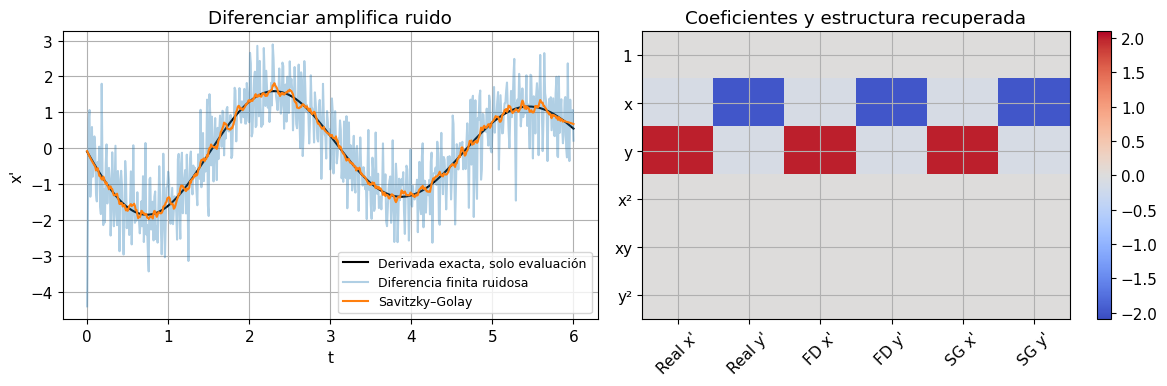

In [3]:
sigma = 0.01
Zruido = Z+rng.normal(0, sigma, Z.shape)
limite_train = 601
Ztrain = Zruido[:limite_train]
ttrain = t[:limite_train]
ventana, orden_poly = 21, 3
Zsuave = savgol_filter(Ztrain, ventana, orden_poly, axis=0)
dZ_sg = savgol_filter(Ztrain, ventana, orden_poly, deriv=1, delta=dt, axis=0)
dZ_fd = np.gradient(Ztrain, dt, axis=0, edge_order=2)
interior = slice(ventana//2, -(ventana//2))
Xi_sg = stlsq(biblioteca(Zsuave[interior]), dZ_sg[interior], umbral=0.05)
Xi_fd = stlsq(biblioteca(Ztrain[interior]), dZ_fd[interior], umbral=0.05)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ttrain, derivada_exacta(Z[:limite_train])[:, 0], "k", label="Derivada exacta, solo evaluación")
axes[0].plot(ttrain, dZ_fd[:, 0], alpha=0.35, label="Diferencia finita ruidosa")
axes[0].plot(ttrain, dZ_sg[:, 0], label="Savitzky–Golay")
axes[0].set(xlabel="t", ylabel="x'", title="Diferenciar amplifica ruido"); axes[0].legend(fontsize=9)
im = axes[1].imshow(np.c_[Xi_real, Xi_fd, Xi_sg], aspect="auto", cmap="coolwarm", vmin=-2.1, vmax=2.1)
axes[1].set_yticks(np.arange(6), nombres)
axes[1].set_xticks(np.arange(6), ["Real x'", "Real y'", "FD x'", "FD y'", "SG x'", "SG y'"], rotation=45)
axes[1].set(title="Coeficientes y estructura recuperada")
fig.colorbar(im, ax=axes[1]); plt.tight_layout(); plt.show()
print("Error de coeficientes FD:", np.linalg.norm(Xi_fd-Xi_real))
print("Error de coeficientes SG:", np.linalg.norm(Xi_sg-Xi_real))

## 6. Probar una trayectoria con condición inicial nueva

Un buen ajuste de derivadas de entrenamiento no garantiza predicciones estables. Integraremos la ecuación aprendida desde $(0.8,-0.6)$, que no coincide con la condición de entrenamiento, durante cuatro unidades de tiempo. La verdad exacta solo se usa para evaluar.

La evaluación incluye error de trayectoria y energía, porque coeficientes pequeños erróneos pueden acumularse con el tiempo. Una validación seria distingue error de ajuste local, error de rollout y estabilidad para condiciones nuevas.

RMSE de trayectoria nueva: 0.0012499779873620595


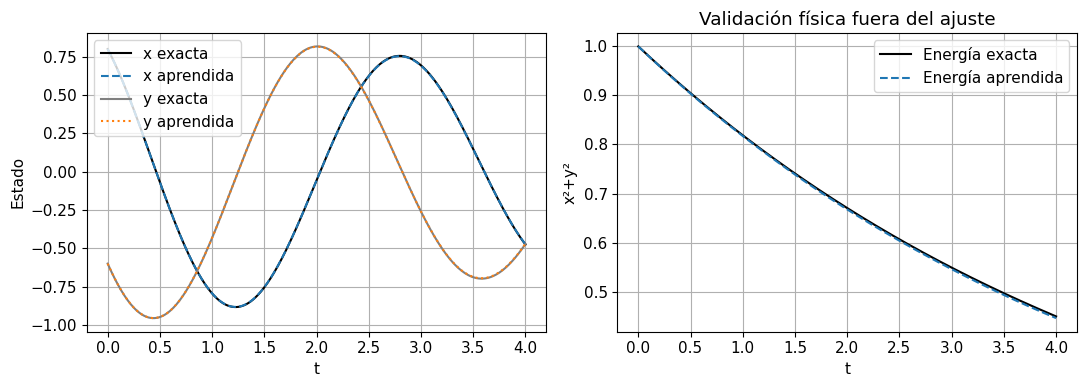

In [4]:
t_nuevo = np.linspace(0, 4, 401)
inicial_nueva = [0.8, -0.6]
Zverdad_nueva = trayectoria(t_nuevo, inicial_nueva)

def rhs_aprendido(tiempo, estado, Xi):
    return (biblioteca(np.asarray(estado)[None, :]) @ Xi).ravel()

sol = solve_ivp(lambda tt, zz: rhs_aprendido(tt, zz, Xi_sg), (0, 4), inicial_nueva, t_eval=t_nuevo, rtol=1e-9, atol=1e-11)
if not sol.success: raise RuntimeError(sol.message)
Zpred = sol.y.T
print("RMSE de trayectoria nueva:", np.sqrt(np.mean((Zpred-Zverdad_nueva)**2)))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t_nuevo, Zverdad_nueva[:, 0], "k", label="x exacta")
axes[0].plot(t_nuevo, Zpred[:, 0], "--", label="x aprendida")
axes[0].plot(t_nuevo, Zverdad_nueva[:, 1], color="gray", label="y exacta")
axes[0].plot(t_nuevo, Zpred[:, 1], ":", label="y aprendida")
axes[0].set(xlabel="t", ylabel="Estado"); axes[0].legend()
axes[1].plot(t_nuevo, np.sum(Zverdad_nueva**2, axis=1), "k", label="Energía exacta")
axes[1].plot(t_nuevo, np.sum(Zpred**2, axis=1), "--", label="Energía aprendida")
axes[1].set(xlabel="t", ylabel="x²+y²", title="Validación física fuera del ajuste")
axes[1].legend(); plt.tight_layout(); plt.show()

## 7. Repetir semillas y estudiar sensibilidad

Repetiremos el ajuste con distintos niveles de ruido y diez semillas por nivel. Mediremos error de coeficientes y recuperación del soporte: las posiciones donde los coeficientes son distintos de cero. Un coeficiente correcto pero sesgado es diferente de seleccionar términos equivocados.

El umbral y la ventana permanecerán fijos durante esta evaluación. Ajustarlos después de mirar los resultados de prueba convertiría esa prueba en validación. Con solo diez semillas, una fracción de éxito tiene bastante incertidumbre; no es una probabilidad universal de éxito del método.

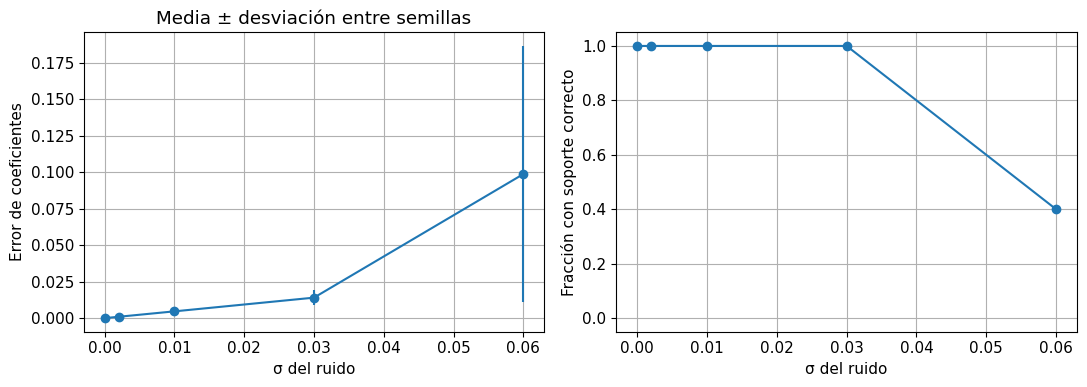

In [5]:
niveles_ruido = [0.0, 0.002, 0.01, 0.03, 0.06]
errors, exitos = [], []
soporte_real = np.abs(Xi_real) > 1e-12
for sig in niveles_ruido:
    e_nivel, s_nivel = [], []
    for seed in range(10):
        rr = np.random.default_rng(100+seed)
        zz = Z[:limite_train]+rr.normal(0, sig, (limite_train, 2))
        zs = savgol_filter(zz, ventana, orden_poly, axis=0)
        dz = savgol_filter(zz, ventana, orden_poly, deriv=1, delta=dt, axis=0)
        xi = stlsq(biblioteca(zs[interior]), dz[interior], umbral=0.05)
        e_nivel.append(np.linalg.norm(xi-Xi_real))
        s_nivel.append(np.array_equal(np.abs(xi)>1e-12, soporte_real))
    errors.append(e_nivel); exitos.append(np.mean(s_nivel))
errors = np.array(errors)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].errorbar(niveles_ruido, errors.mean(axis=1), yerr=errors.std(axis=1, ddof=1), fmt="o-")
axes[0].set(xlabel="σ del ruido", ylabel="Error de coeficientes", title="Media ± desviación entre semillas")
axes[1].plot(niveles_ruido, exitos, "o-")
axes[1].set(xlabel="σ del ruido", ylabel="Fracción con soporte correcto", ylim=(-0.05, 1.05))
plt.tight_layout(); plt.show()

## 8. Identificabilidad y diseño de datos

Una trayectoria cerca de un equilibrio puede no excitar términos suficientes para distinguirlos. Si siempre observamos $y=0$, columnas como $y$ y $xy$ desaparecen. Si observamos un rango diminuto de $x$, una función puede parecer lineal aunque no lo sea.

Inspeccionar singular values de la biblioteca da un diagnóstico numérico; varias condiciones iniciales pueden ampliar la región explorada. Aun así, identificar una ley en una región no garantiza extrapolación. El método devuelve una explicación dentro de una clase candidata y los datos disponibles.

In [6]:
singulares = np.linalg.svd(biblioteca(Zsuave[interior]), compute_uv=False)
print("Valores singulares de la biblioteca:", singulares)
print("Condición aproximada de la biblioteca:", singulares[0]/singulares[-1])
# Un diseño degenerado como ejemplo controlado: todos los estados en el origen.
Theta_degenerada = biblioteca(np.zeros((50, 2)))
print("Rango en el origen:", np.linalg.matrix_rank(Theta_degenerada), "de", Theta_degenerada.shape[1])

Valores singulares de la biblioteca: [26.17299057 13.57696157 12.34752285  7.17645183  5.10188296  2.66755524]
Condición aproximada de la biblioteca: 9.811602100633026
Rango en el origen: 1 de 6


## 9. Comparación con la fuente y registro de desviaciones

La fuente primaria presenta un marco general para descubrir ecuaciones mediante funciones candidatas y regresión dispersa. Aquí conservamos esa estructura y usamos un oscilador de dos estados con solución exacta. Elegimos nuestras propias condiciones, duración, ruido, biblioteca, ventana y umbral.

Por tanto, el resultado que verificamos es recuperación en este experimento reducido. Para reproducir una figura específica habría que recuperar sus datos o regenerarlos con los mismos parámetros, igualar tratamiento de derivadas, normalización y selección de hiperparámetros, y comparar métricas con tolerancias documentadas.

## 10. Un informe de reproducción útil

Incluye referencia y versión, afirmación objetivo, entorno, procedencia de datos, protocolo de ejecución, decisiones propias, métricas, resultados y fallos. Un resultado negativo bien localizado es informativo: por ejemplo, recuperar soporte con derivada exacta pero fallar con derivada estimada dirige la investigación hacia diferenciación y ruido.

No selecciones únicamente la semilla favorable. No cambies biblioteca o umbral para ajustar retrospectivamente un caso sin explicarlo. Y no confundas que tu código corre con que reproduce una afirmación del artículo.

## 11. Conexión con SciML

SINDy aprende estructura interpretable de una dinámica. Una PINN suele aproximar un estado y puede estimar parámetros, mientras un neural operator aprende mapas entre funciones. Pueden combinarse: usar un modelo conocido para generar datos, aprender una corrección y asimilar observaciones.

Una ecuación dispersa puede resultar barata de integrar, pero su extrapolación y estabilidad requieren validación. En modelos con conservación, conviene incorporar o comprobar esas restricciones además de minimizar error de derivadas.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../20_INVESTIGACION/20_1_papers.ipynb) | [⏩](../20_INVESTIGACION/20_3_Diseño_experimental.ipynb) |